> **Telecommunication Lab Exam | Experiment 7**  
> Based on *Telecommunication-Lab.pdf*, PDF pages 21–24.  
> **Use:** Read the theory → run the two code cells → identify the output → practice the viva answers.  
> **Software:** Python 3, Jupyter/Colab, `numpy`, `matplotlib`. **Only Exp 1 optionally needs `scipy`.**


# Experiment 7 — Frequency Hopping Spread Spectrum (FHSS)

**Aim (manual):** Implement Frequency Hopping Spread Spectrum in MATLAB.

## 1. Theory / working principle

**FHSS** changes the carrier frequency among a set of permitted frequencies according to a hopping sequence. The transmitter and receiver must follow the same hopping pattern and timing.

**Transmitter (manual block diagram):** Binary data → M-ary FSK modulator → mixer with PN-controlled frequency synthesizer → FH/MFSK signal.  
**Receiver (manual block diagram):** Mix with synchronized local synthesizer → band-pass filter → noncoherent M-ary FSK detector → estimated binary data.

The *program in the manual* actually demonstrates a **BPSK signal multiplied by a frequency-hopping waveform**, rather than a full M-ary FSK detector. This exam-ready Python notebook follows that simulation style: it uses a fixed, reproducible hop sequence and adds an ideal recovery check.

### Essential mathematical model for this demonstration

Polar data:

$$d_k = 2b_k - 1$$

Hop frequency chosen at time slot $k$:

$$f_h(k)\in\{f_1,f_2,\dots,f_M\}$$

BPSK signal and hopping signal:

$$s_{\mathrm{BPSK}}(t)=d_k\cos(2\pi f_0 t),\qquad h_k(t)=\cos(2\pi f_h(k)t)$$

Waveform shown by this **multiplication-based demonstration**:

$$s_{\mathrm{demo}}(t)=s_{\mathrm{BPSK}}(t)\,h_k(t)$$

The hop interval and hop rate are related by:

$$R_h=\frac{1}{T_h}$$

**Important distinction:** Multiplying two cosines creates sum-and-difference frequency components. A full frequency-hopping radio is more than this classroom simulation.


## 2. Input, hops and manual correspondence

This compact notebook uses **10 data bits** so you can explain every step easily. The manual's longer MATLAB example uses **20 random bits** and an older random-integer function; therefore your exact bit values and plots need not match the manual's random run.

| Quantity | This reproducible demo |
|---|---|
| Binary data | `1 0 1 1 0 0 1 0 1 1` |
| Available hop frequencies | `1, 2, 3, 4, 6, 12, 24` cycles/bit |
| Hop indices | `7, 3, 5, 1, 4, 6, 2, 7, 2, 5` |
| Chosen frequencies | `24, 3, 6, 1, 4, 12, 2, 24, 2, 6` |
| Plot count | 4 |

**Why fixed hops?** They serve the same visual learning goal and produce identical expected plots on every run. They **represent** a chosen hopping sequence; they are **not** a generated PN/LFSR sequence. This notebook uses an *ideal, synchronized* dehopping detector as an additional correctness check.


## 3. Runnable Python implementation

**Run the next cell** to compute the signal and print essential results. The following cell draws the output waveforms. Use **Run All** to execute both in order.

Hop Frequencies: [24  3  6  1  4 12  2 24  2  6]
Sent Bits:       [1 0 1 1 0 0 1 0 1 1]
Recovered Bits:  [1, 0, 1, 1, 0, 0, 1, 0, 1, 1]


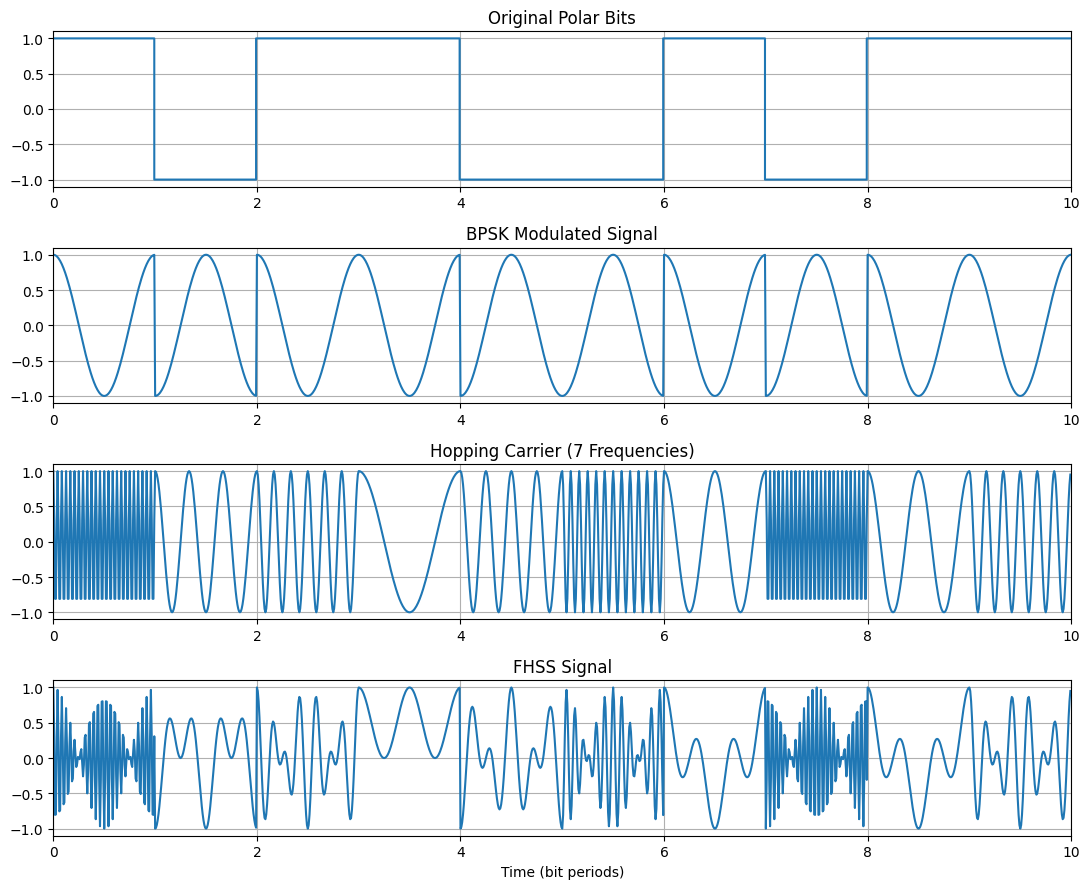

In [ ]:

"""Experiment 7: FHSS using BPSK and seven hopping frequencies."""
import numpy as np
import matplotlib.pyplot as plt

# 1. Message bits, hop order and available frequencies
bits = np.array([1, 0, 1, 1, 0, 0, 1, 0, 1, 1])
hop_index = np.array([7, 3, 5, 1, 4, 6, 2, 7, 2, 5])
freq = np.array([1, 2, 3, 4, 6, 12, 24])  # cycles per bit period
N = 120                                       # samples per bit (one hop)
t_bit = np.arange(N) / N                      # time for one bit
t = np.arange(len(bits) * N) / N              # time for all bits

# 2. Binary Data -> Polar Bits -> BPSK Carrier
polar = np.repeat(2 * bits - 1, N)
base_carrier = np.tile(np.cos(2 * np.pi * t_bit), len(bits))
bpsk = polar * base_carrier

# 3. Frequency-Hopping Carrier
hop_carrier = np.zeros_like(t)

for i, hop in enumerate(hop_index):
    start, end = i * N, (i + 1) * N
    hop_carrier[start:end] = np.cos(2 * np.pi * freq[hop-1] * t_bit)

# 4. FHSS Modulation (Mix BPSK with Hopping Carrier)
fhss = bpsk * hop_carrier

# 5. Optional: De-hopping and Data Recovery
received = []
for i in range(len(bits)):
    start, end = i * N, (i + 1) * N
    score = np.sum(fhss[start:end] * hop_carrier[start:end] * base_carrier[start:end])
    received.append(int(score > 0))

# 6. Display Results
print("Hop Frequencies:", freq[hop_index-1])
print("Sent Bits:      ", bits)
print("Recovered Bits: ", received)

# 7. Plot FHSS Waveforms
fig, ax = plt.subplots(4, 1, figsize=(11, 9))

ax[0].step(t, polar)
ax[0].set_title("Original Polar Bits")

ax[1].plot(t, bpsk)
ax[1].set_title("BPSK Modulated Signal")

ax[2].plot(t, hop_carrier)
ax[2].set_title("Hopping Carrier (7 Frequencies)")

ax[3].plot(t, fhss)
ax[3].set_title("FHSS Signal")

for a in ax:
    a.grid(True)
    a.set_xlim(0, len(bits))

ax[-1].set_xlabel("Time (bit periods)")
plt.tight_layout()
plt.show()


## 4. Expected output and interpretation

1. **Original polar bits:** high for a `1`, low for a `0`.
2. **BPSK signal:** sinusoidal carrier with a $180^\circ$ phase flip for polar `-1` bits.
3. **Hopping carrier:** waveform oscillation rate changes from slot to slot, following the 7-frequency set.
4. **FHSS signal:** mixed waveform changes with the data and the hopping carrier.

You should see **recovered bits `1011001011`**, identical to the input, in the ideal no-noise model. Explain the **change of hopping rate/frequency**, not the exact appearance of every oscillation.

**Result to write:** A sequence of data bits was transmitted with a hopping-frequency waveform using seven frequencies. The receiver recovered the input correctly under ideal synchronization.

## 5. Viva — short answers

**Q1. What is FHSS?** Spread spectrum using a carrier that changes frequency in a synchronized pattern.  
**Q2. Who controls the hops?** A PN-controlled frequency synthesizer in the conceptual system.  
**Q3. Why hop frequencies?** To improve resilience against narrowband interference/jamming and share spectrum.  
**Q4. What is the hop rate?** Number of frequency changes per second, $R_h=1/T_h$.  
**Q5. How does the receiver recover data?** By synchronized dehopping followed by signal detection.  
**Q6. What happens if synchronization fails?** The receiver follows the wrong hop and may fail to demodulate.  
**Q7. Fast vs slow FHSS?** In fast hopping there are multiple hops per symbol; in slow hopping there can be multiple symbols per hop.  
**Q8. FHSS vs DSSS?** FHSS varies carrier frequency; DSSS multiplies data by a rapid PN chip sequence.

**Practice:** On the third plot, point out two adjacent intervals with visibly different carrier frequencies.
